# Q4 — 3D Scene Reconstruction with COLMAP

**Objective:** Perform sparse (and optionally dense) 3-D reconstruction of a real scene
from a set of unordered photographs using **COLMAP** via its Python bindings (`pycolmap`).

**Pipeline:**
1. **Feature extraction** — SIFT keypoints + descriptors for each image
2. **Feature matching** — Exhaustive pairwise matching across all image pairs
3. **Sparse reconstruction (SfM)** — Incremental Structure-from-Motion recovers camera poses
   and a sparse 3-D point cloud
4. **Visualisation** — Display point cloud and camera frustums with Open3D and matplotlib

**Dataset:** 11 real photos of Sceaux Castle (a standard SfM benchmark) stored in
`q4_data/images/`.

In [2]:
# Download the Sceaux Castle image dataset (run this cell first).
# The notebook stores all generated files in ./q4_data next to the notebook's working directory.
import urllib.request
import zipfile
from pathlib import Path

BASE_DIR = Path.cwd() / "q4_data"
IMAGE_DIR = BASE_DIR / "images"
BASE_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

def find_images(folder):
    extensions = {".jpg", ".jpeg", ".png"}
    return sorted(p for p in folder.iterdir()
                  if p.is_file() and p.suffix.lower() in extensions)

images = find_images(IMAGE_DIR)
if not images:
    URL = "https://github.com/openMVG/ImageDataset_SceauxCastle/archive/refs/heads/master.zip"
    ZIP_PATH = BASE_DIR / "sceaux_dataset.zip"
    print("Image directory is empty. Downloading Sceaux Castle dataset...")
    try:
        urllib.request.urlretrieve(URL, ZIP_PATH)
        with zipfile.ZipFile(ZIP_PATH, "r") as archive:
            for member in archive.namelist():
                if Path(member).suffix.lower() in {".jpg", ".jpeg", ".png"}:
                    target = IMAGE_DIR / Path(member).name
                    if not target.exists():
                        target.write_bytes(archive.read(member))
        ZIP_PATH.unlink(missing_ok=True)
    except Exception as exc:
        raise RuntimeError(
            "Dataset download failed. Check your internet connection, then rerun this cell."
        ) from exc
    images = find_images(IMAGE_DIR)

if not images:
    raise RuntimeError(f"No images found in {IMAGE_DIR.resolve()}.")

print(f"Dataset ready: {len(images)} images")
print(f"Image folder: {IMAGE_DIR.resolve()}")
for image_path in images:
    print(" -", image_path.name)


Image directory is empty. Downloading Sceaux Castle dataset...
Dataset ready: 11 images
Image folder: E:\BS AI\Seventh Semester\CV\Lab\Lab 7\q4_data\images
 - 100_7100.JPG
 - 100_7101.JPG
 - 100_7102.JPG
 - 100_7103.JPG
 - 100_7104.JPG
 - 100_7105.JPG
 - 100_7106.JPG
 - 100_7107.JPG
 - 100_7108.JPG
 - 100_7109.JPG
 - 100_7110.JPG


In [3]:
# Import required libraries. If this cell reports a missing package, install it
# in a terminal with: python -m pip install pycolmap open3d opencv-python matplotlib numpy
try:
    import pycolmap
    import open3d as o3d
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
except ImportError as exc:
    raise ImportError(
        "A required package is missing. Run in your environment: "
        "python -m pip install pycolmap open3d opencv-python matplotlib numpy"
    ) from exc

print("pycolmap:", getattr(pycolmap, "__version__", "version not exposed"))
print("open3d:", o3d.__version__)
print("OpenCV:", cv2.__version__)
print("All libraries imported successfully!")


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
pycolmap: 4.2.1
open3d: 0.20.0
OpenCV: 5.0.0
All libraries imported successfully!


In [4]:
import os
import shutil
import time
import sqlite3
from pathlib import Path

import numpy as np
import cv2
import pycolmap
import open3d as o3d
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

BASE_DIR = Path.cwd() / "q4_data"
IMAGE_DIR = BASE_DIR / "images"
OUTPUT_DIR = BASE_DIR / "sparse"
DATABASE = BASE_DIR / "database.db"

BASE_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Confirm inputs exist before clearing previous reconstruction outputs.
images = sorted(p for p in IMAGE_DIR.iterdir()
                if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"})
if not images:
    raise RuntimeError(
        f"No input images found in {IMAGE_DIR.resolve()}. "
        "Run the dataset download cell (cell 2) first."
    )

# Clean only generated reconstruction outputs; keep downloaded images.
if DATABASE.exists():
    DATABASE.unlink()
for item in OUTPUT_DIR.iterdir():
    if item.is_dir():
        shutil.rmtree(item)
    else:
        item.unlink()

print(f"Found {len(images)} images in {IMAGE_DIR.resolve()}")
for img in images:
    print(" ", img.name)


Found 11 images in E:\BS AI\Seventh Semester\CV\Lab\Lab 7\q4_data\images
  100_7100.JPG
  100_7101.JPG
  100_7102.JPG
  100_7103.JPG
  100_7104.JPG
  100_7105.JPG
  100_7106.JPG
  100_7107.JPG
  100_7108.JPG
  100_7109.JPG
  100_7110.JPG


## 1 — Dataset Preview

The 11 images are of Sceaux Castle (France), a standard Structure-from-Motion benchmark.
They were taken from various viewpoints around the castle facade, giving good overlap for
3-D reconstruction.

In [5]:
# The dataset and output folders were created in the first setup cells.
print("Working directory:", Path.cwd())
print("Dataset folder:", IMAGE_DIR.resolve())
print("Sparse output folder:", OUTPUT_DIR.resolve())
print("Input images:", len(images))


Working directory: e:\BS AI\Seventh Semester\CV\Lab\Lab 7
Dataset folder: E:\BS AI\Seventh Semester\CV\Lab\Lab 7\q4_data\images
Sparse output folder: E:\BS AI\Seventh Semester\CV\Lab\Lab 7\q4_data\sparse
Input images: 11


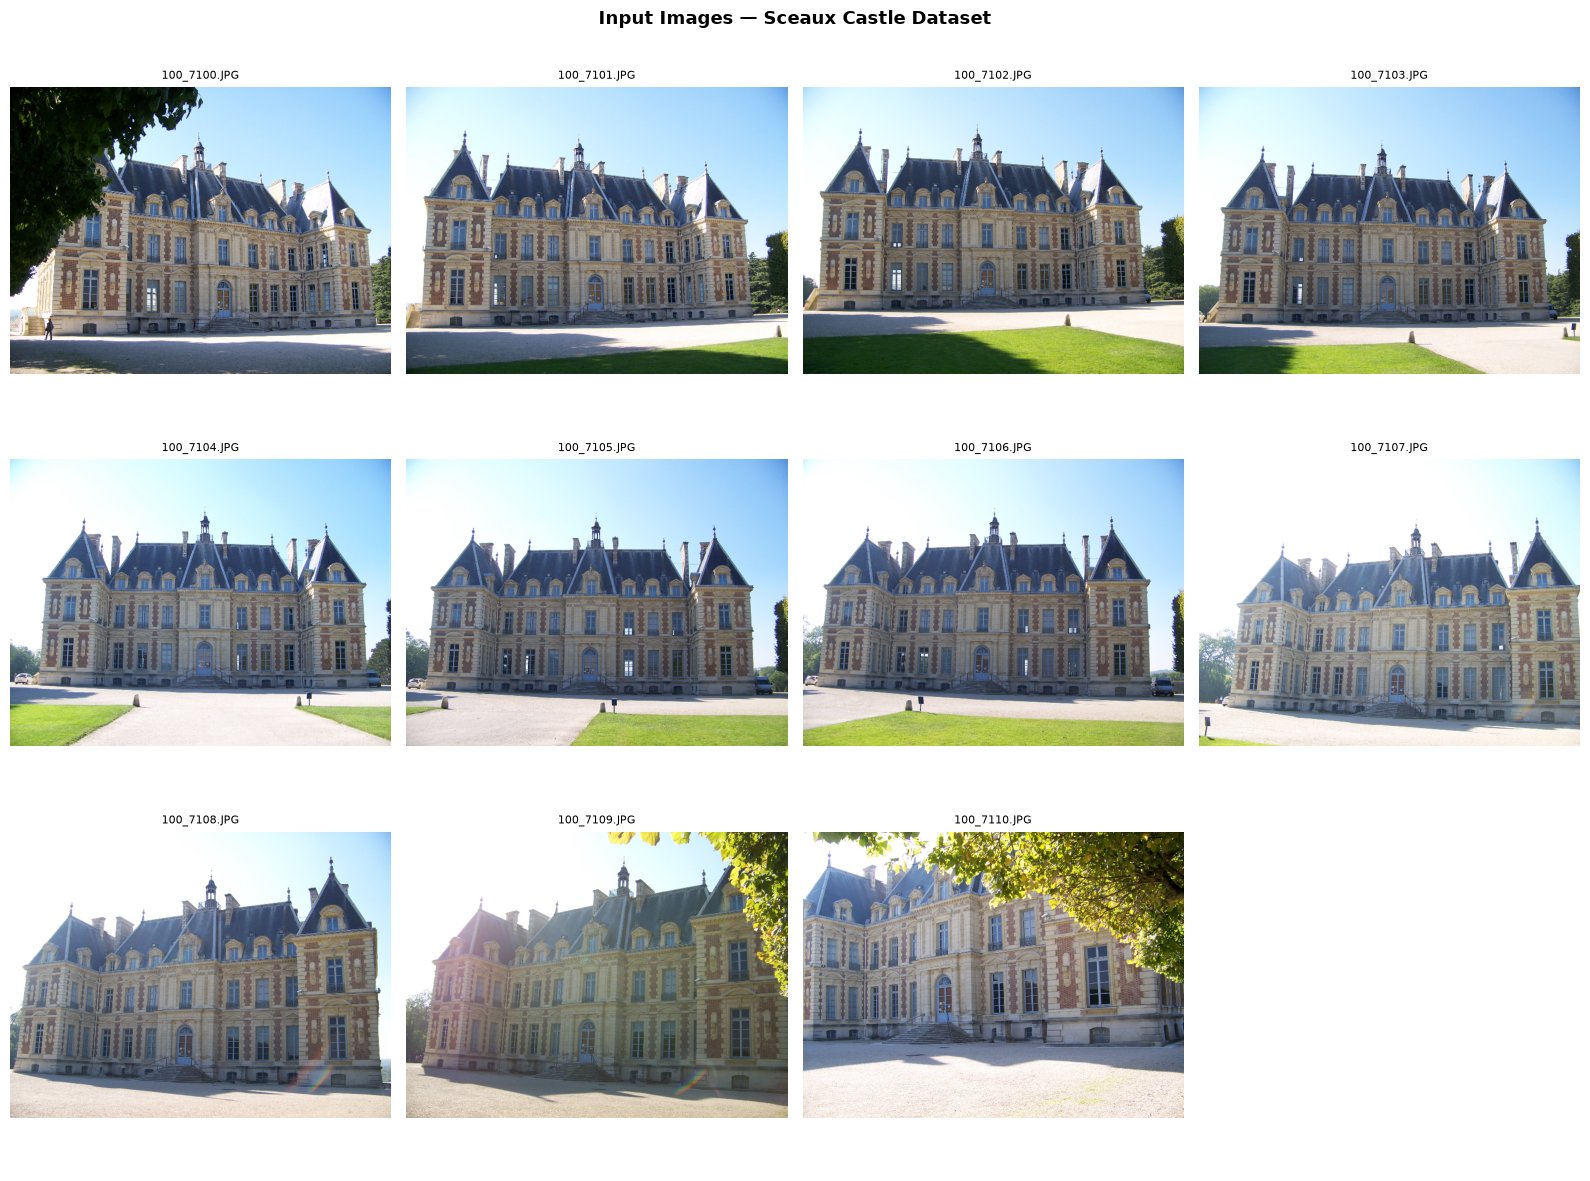

Saved → q4_data/q4_input_images.png


In [6]:
# ------------------------------------------------------------------
# 1  Show a grid of the input images
# ------------------------------------------------------------------
ncols = 4
nrows = (len(images) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 4))
for ax, imgp in zip(axes.flat, images):
    img = cv2.imread(str(imgp))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # downsample for display
    h, w = img.shape[:2]
    thumb = cv2.resize(img, (w//4, h//4))
    ax.imshow(thumb)
    ax.set_title(imgp.name, fontsize=8)
    ax.axis("off")
for ax in list(axes.flat)[len(images):]:
    ax.axis("off")
plt.suptitle("Input Images — Sceaux Castle Dataset", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("q4_data/q4_input_images.png", dpi=70, bbox_inches="tight")
plt.show()
print(f"Saved → q4_data/q4_input_images.png")

## 2 — Feature Extraction (SIFT)

`pycolmap.extract_features` runs SIFT on each image and stores:
- **keypoints** (position, scale, orientation)
- **128-D descriptors**

in a SQLite database.

SIFT was chosen for its robustness to rotation, scale, and moderate viewpoint changes —
exactly the conditions found across photos of a building taken from different distances.

In [7]:
# ------------------------------------------------------------------
# 2  Extract SIFT features
# ------------------------------------------------------------------
print("Extracting features …")
t0 = time.time()

opts = pycolmap.SiftExtractionOptions()
opts.max_num_features = 8192   # keep up to 8 k features per image

pycolmap.extract_features(
    database_path  = DATABASE,
    image_path     = IMAGE_DIR,
    camera_mode    = pycolmap.CameraMode.AUTO,
    extraction_options = pycolmap.FeatureExtractionOptions(sift=opts),
)

t_extract = time.time() - t0
print(f"Feature extraction done in {t_extract:.1f}s")

# Count features stored in the database
import sqlite3
with sqlite3.connect(str(DATABASE)) as con:
    n_kp = con.execute("SELECT SUM(rows) FROM keypoints").fetchone()[0]
    n_img = con.execute("SELECT COUNT(*) FROM images").fetchone()[0]
print(f"Images in DB : {n_img}")
print(f"Total keypoints : {n_kp:,}")

Extracting features …
Feature extraction done in 121.7s
Images in DB : 11
Total keypoints : 118,875


## 3 — Feature Matching (Exhaustive)

`pycolmap.match_exhaustive` compares every image pair and finds corresponding
keypoints using nearest-neighbour descriptor matching and Lowe's ratio test,
then validates geometry with the **Essential / Fundamental matrix** test.

For 11 images this means 11×10/2 = **55 image pairs** are tested.

In [8]:
# ------------------------------------------------------------------
# 3  Exhaustive matching
# ------------------------------------------------------------------
print("Matching features exhaustively …")
t0 = time.time()

pycolmap.match_exhaustive(database_path=DATABASE)

t_match = time.time() - t0
print(f"Matching done in {t_match:.1f}s")

with sqlite3.connect(str(DATABASE)) as con:
    n_pairs = con.execute("SELECT COUNT(*) FROM matches").fetchone()[0]
    n_good  = con.execute(
        "SELECT COUNT(*) FROM two_view_geometries WHERE rows > 0"
    ).fetchone()[0]
print(f"Pairs attempted : {n_pairs}")
print(f"Pairs verified  : {n_good}  (geometry check passed)")

Matching features exhaustively …
Matching done in 76.7s
Pairs attempted : 55
Pairs verified  : 55  (geometry check passed)


## 4 — Sparse Reconstruction (Incremental SfM)

`pycolmap.incremental_mapping` runs the full **Structure-from-Motion** pipeline:

1. **Seed image pair** — start from the best-overlapping pair
2. **Triangulation** — back-project matched features into 3-D points
3. **Register new images** — solve PnP (perspective-n-point) to add each new view
4. **Bundle adjustment** — jointly optimise camera poses and 3-D point positions
   to minimise total reprojection error

Output: a folder `q4_data/sparse/0/` containing:
- `cameras.bin` — intrinsic parameters for each camera
- `images.bin` — pose (R, t) for each registered image
- `points3D.bin` — sparse 3-D point cloud

In [9]:
# ------------------------------------------------------------------
# 4  Incremental mapping (SfM)
# ------------------------------------------------------------------
print("Running incremental SfM …")
t0 = time.time()

maps = pycolmap.incremental_mapping(
    database_path = DATABASE,
    image_path    = IMAGE_DIR,
    output_path   = OUTPUT_DIR,
)

t_sfm = time.time() - t0
print(f"SfM done in {t_sfm:.1f}s")
print(f"Reconstructions found: {len(maps)}")
if not maps:
    raise RuntimeError("COLMAP produced no reconstruction. Check image overlap and feature-matching results.")
for model_id, rec in maps.items():
    print(f"  Model {model_id}: "
          f"{rec.num_reg_images()} registered images, "
          f"{rec.num_points3D()} 3-D points")

Running incremental SfM …
SfM done in 25.1s
Reconstructions found: 1
  Model 0: 11 registered images, 7883 3-D points


## 5 — Inspecting the Reconstruction

We load the best (largest) reconstruction and extract:
- **Camera intrinsics** (focal length, principal point)
- **Camera extrinsics** (rotation, translation) for each registered image
- **3-D point cloud** (XYZ + RGB colour)

In [10]:
# ------------------------------------------------------------------
# 5-A  Load the largest reconstruction
# ------------------------------------------------------------------
# models are keyed 0, 1, … — take the one with most registered images
best_id  = max(maps, key=lambda k: maps[k].num_reg_images())
rec      = maps[best_id]

print(f"Using reconstruction {best_id}")
print(f"  Registered images : {rec.num_reg_images()}")
print(f"  3-D points        : {rec.num_points3D():,}")

# --- cameras (intrinsics) ---
print("\n--- Cameras ---")
for cam_id, cam in rec.cameras.items():
    print(f"  Camera {cam_id}: {cam.model_name}  "
          f"{cam.width}×{cam.height}  "
          f"params={[round(float(p),2) for p in cam.params]}")

# --- images (poses) ---
# Note: cam_from_world is a method in pycolmap 4 — call it with ()
print("\n--- Registered images ---")
for img_id, img in sorted(rec.images.items()):
    t = img.cam_from_world().translation
    print(f"  [{img_id:2d}] {img.name:20s}  t=({t[0]:6.2f},{t[1]:6.2f},{t[2]:6.2f})")

Using reconstruction 0
  Registered images : 11
  3-D points        : 7,883

--- Cameras ---
  Camera 1: SIMPLE_RADIAL  2832×2128  params=[2973.34, 1416.0, 1064.0, -0.16]

--- Registered images ---
  [ 1] 100_7103.JPG          t=(  2.46,  0.34,  1.61)
  [ 2] 100_7101.JPG          t=(  4.44,  0.28,  1.83)
  [ 3] 100_7102.JPG          t=(  3.19,  0.26,  1.84)
  [ 4] 100_7100.JPG          t=(  6.30,  0.34,  1.81)
  [ 5] 100_7104.JPG          t=(  1.19,  0.32,  1.54)
  [ 6] 100_7105.JPG          t=( -0.06,  0.31,  1.48)
  [ 7] 100_7106.JPG          t=( -1.21,  0.22,  1.20)
  [ 8] 100_7107.JPG          t=( -2.41,  0.08,  0.60)
  [ 9] 100_7108.JPG          t=( -3.87, -0.09,  0.06)
  [10] 100_7109.JPG          t=( -5.18, -0.23,  0.06)
  [11] 100_7110.JPG          t=( -6.38,  0.09, -0.83)


In [11]:
# ------------------------------------------------------------------
# 5-B  Extract point cloud with colours
# ------------------------------------------------------------------
pts3d = rec.points3D   # dict: point3D_id -> Point3D
if not pts3d:
    raise RuntimeError("The selected reconstruction contains no 3-D points.")

xyz   = np.array([[p.xyz[0], p.xyz[1], p.xyz[2]] for p in pts3d.values()], dtype=np.float64)
rgb   = np.array([[p.color[0], p.color[1], p.color[2]] for p in pts3d.values()], dtype=np.uint8)
err   = np.array([p.error for p in pts3d.values()], dtype=np.float64)

print(f"Point cloud: {len(xyz):,} points")
print(f"XYZ range   X:[{xyz[:,0].min():.2f}, {xyz[:,0].max():.2f}]  "
      f"Y:[{xyz[:,1].min():.2f}, {xyz[:,1].max():.2f}]  "
      f"Z:[{xyz[:,2].min():.2f}, {xyz[:,2].max():.2f}]")
print(f"Mean reprojection error per point: {err.mean():.4f} px")
print(f"Points with error < 1px : {(err < 1).sum():,} ({100*(err<1).mean():.1f}%)")

Point cloud: 7,883 points
XYZ range   X:[-16.40, 3.03]  Y:[-3.21, 23.41]  Z:[3.90, 165.02]
Mean reprojection error per point: 0.6092 px
Points with error < 1px : 6,867 (87.1%)


## 6 — Visualising the Point Cloud

We produce two visualisations:

1. **matplotlib 3-D scatter** — shows the coloured point cloud plus camera
   positions and viewing-direction arrows
2. **Open3D point cloud** — saved as a `.ply` file for external viewing

In [12]:
# ------------------------------------------------------------------
# 6-A  Extract camera centres for display
# ------------------------------------------------------------------
cam_centres = []
cam_dirs    = []
for img in rec.images.values():
    # Camera centre in world coords via pycolmap helper
    C   = img.projection_center()
    # Principal-axis direction (Z-axis of camera in world coords): R^T @ [0,0,1]
    R   = img.cam_from_world().rotation.matrix()
    z_w = R.T @ np.array([0., 0., 1.])
    cam_centres.append(C)
    cam_dirs.append(z_w)

cam_centres = np.array(cam_centres)
cam_dirs    = np.array(cam_dirs)
print(f"Camera centres extracted: {len(cam_centres)}")

Camera centres extracted: 11


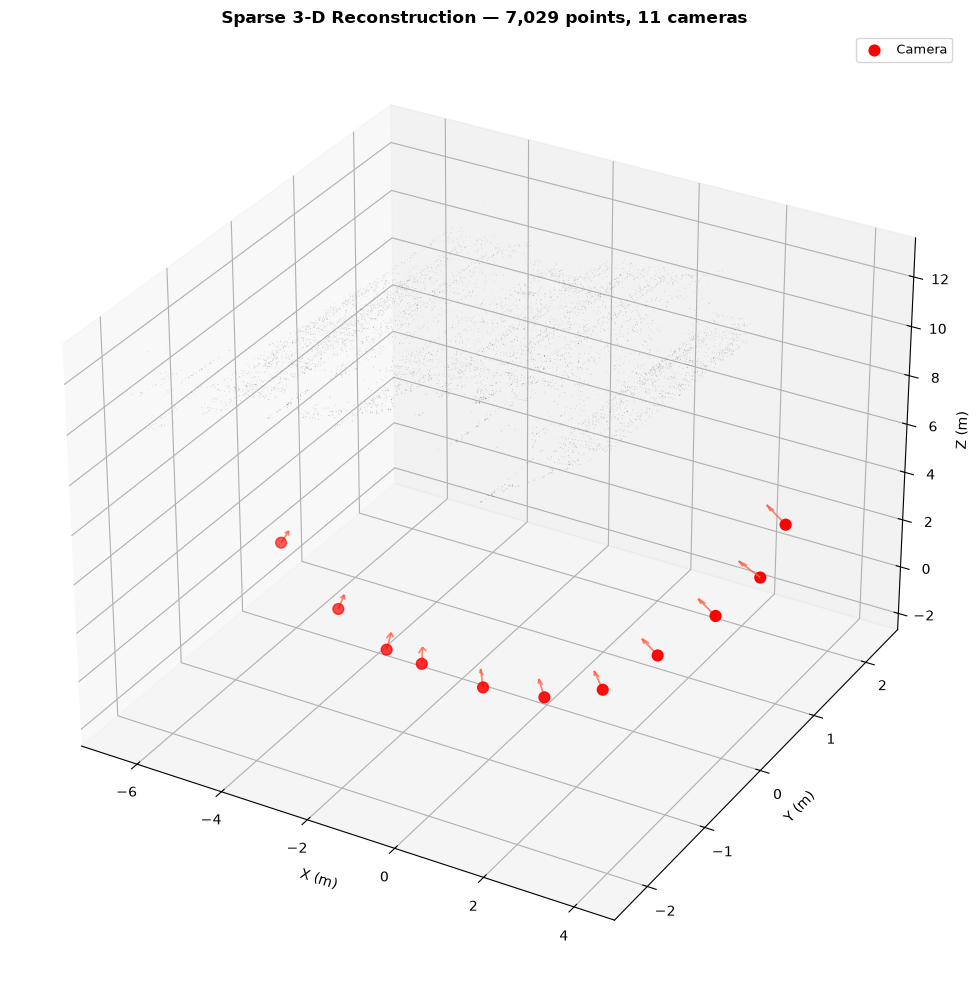

Saved → q4_data/q4_point_cloud_3d.png


In [13]:
# ------------------------------------------------------------------
# 6-B  Matplotlib 3-D scatter plot
# ------------------------------------------------------------------
# Remove extreme outliers (top/bottom 2 %) for better zoom
pct2  = np.percentile(xyz, 2, axis=0)
pct98 = np.percentile(xyz, 98, axis=0)
mask  = np.all((xyz >= pct2) & (xyz <= pct98), axis=1)
xyz_c = xyz[mask]
rgb_c = rgb[mask]

fig = plt.figure(figsize=(14, 10))
ax  = fig.add_subplot(111, projection="3d")

# Point cloud (subsample for speed)
step = max(1, len(xyz_c) // 5000)
ax.scatter(xyz_c[::step, 0], xyz_c[::step, 1], xyz_c[::step, 2],
           c=rgb_c[::step] / 255.0, s=0.5, alpha=0.6, linewidths=0)

# Camera centres
ax.scatter(cam_centres[:, 0], cam_centres[:, 1], cam_centres[:, 2],
           c="red", s=60, zorder=5, label="Camera")

# Camera viewing direction arrows
arrow_len = (pct98 - pct2).max() * 0.08
for C, d in zip(cam_centres, cam_dirs):
    ax.quiver(C[0], C[1], C[2],
              d[0]*arrow_len, d[1]*arrow_len, d[2]*arrow_len,
              color="tomato", linewidth=1.2, alpha=0.8)

ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_zlabel("Z (m)")
ax.set_title(f"Sparse 3-D Reconstruction — {len(xyz_c):,} points, "
             f"{len(cam_centres)} cameras", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("q4_data/q4_point_cloud_3d.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → q4_data/q4_point_cloud_3d.png")

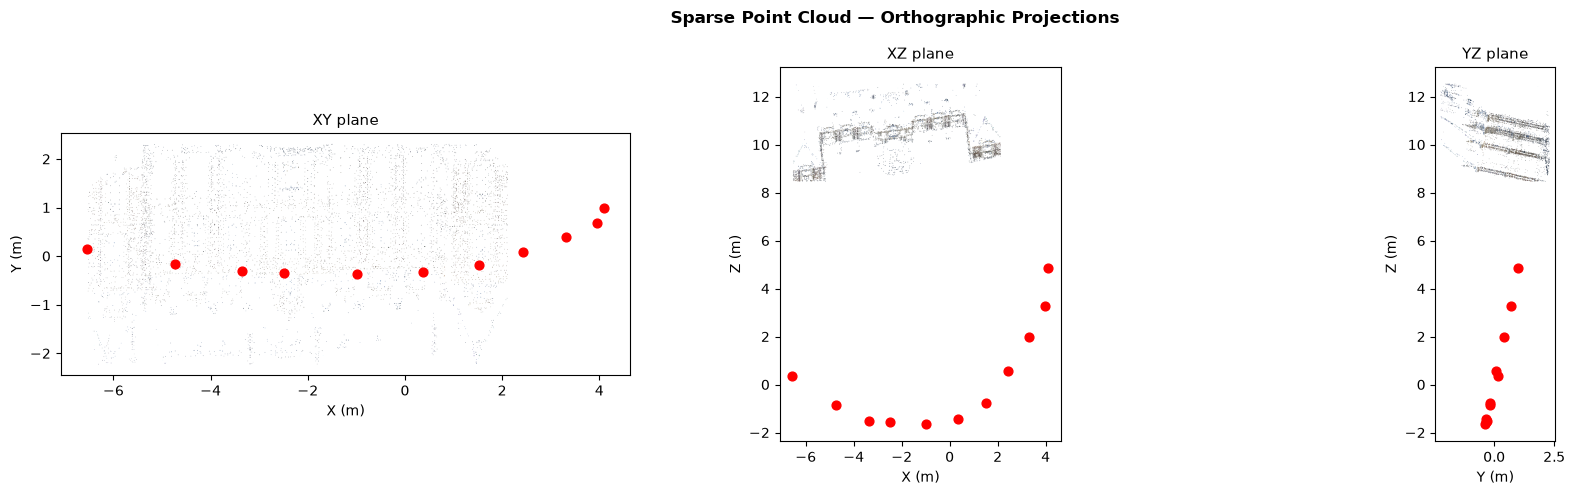

Saved → q4_data/q4_point_cloud_ortho.png


In [14]:
# ------------------------------------------------------------------
# 6-C  Three orthographic projections (XY, XZ, YZ)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
proj_axes = [("X", "Y", 0, 1), ("X", "Z", 0, 2), ("Y", "Z", 1, 2)]
for ax, (xl, yl, xi, yi) in zip(axes, proj_axes):
    ax.scatter(xyz_c[::step, xi], xyz_c[::step, yi],
               c=rgb_c[::step] / 255.0, s=0.3, alpha=0.5, linewidths=0)
    ax.scatter(cam_centres[:, xi], cam_centres[:, yi],
               c="red", s=40, zorder=5)
    ax.set_xlabel(f"{xl} (m)"); ax.set_ylabel(f"{yl} (m)")
    ax.set_title(f"{xl}{yl} plane", fontsize=11)
    ax.set_aspect("equal")
plt.suptitle("Sparse Point Cloud — Orthographic Projections", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("q4_data/q4_point_cloud_ortho.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → q4_data/q4_point_cloud_ortho.png")

## 7 — Saving the Point Cloud as a PLY File

We export the coloured point cloud to a `.ply` file using Open3D so it can be
inspected in MeshLab, CloudCompare, or any 3-D viewer.

In [15]:
# ------------------------------------------------------------------
# 7  Save .ply with Open3D
# ------------------------------------------------------------------
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(xyz.astype(np.float64))
pcd.colors = o3d.utility.Vector3dVector(rgb.astype(np.float64) / 255.0)

ply_path = "q4_data/sparse_cloud.ply"
o3d.io.write_point_cloud(ply_path, pcd)
print(f"Point cloud saved → {ply_path}  ({Path(ply_path).stat().st_size:,} bytes)")

# Simple stats using Open3D
print(f"\nOpen3D point cloud summary:")
print(f"  Points: {len(pcd.points):,}")
bb = pcd.get_axis_aligned_bounding_box()
print(f"  Bounding box: {bb}")

Point cloud saved → q4_data/sparse_cloud.ply  (213,048 bytes)

Open3D point cloud summary:
  Points: 7,883
  Bounding box: AxisAlignedBoundingBox: min: (-16.4009, -3.20984, 3.90103), max: (3.02658, 23.4082, 165.02)


## 8 — Reprojection Error Analysis

For each registered image we re-project all 3-D points that are visible in that
image and measure the average pixel distance to the detected keypoints.
This is the same metric used by COLMAP internally during bundle adjustment.

In [16]:
# ------------------------------------------------------------------
# 8  Per-image reprojection stats
# ------------------------------------------------------------------
img_names  = []
img_errors = []
img_npts   = []

for img_id, img in sorted(rec.images.items()):
    errors_i = []

    # Iterate over all 2-D keypoints that have an associated 3-D point
    for pt2d in img.points2D:
        if not pt2d.has_point3D():
            continue
        p3d_id = pt2d.point3D_id
        if p3d_id not in rec.points3D:
            continue

        # project_point handles all distortion via the camera model
        p3d_xyz = rec.points3D[p3d_id].xyz
        px_proj = img.project_point(p3d_xyz)

        dx = px_proj[0] - pt2d.xy[0]
        dy = px_proj[1] - pt2d.xy[1]
        errors_i.append(float(np.sqrt(dx*dx + dy*dy)))

    if errors_i:
        img_names.append(img.name)
        img_errors.append(float(np.mean(errors_i)))
        img_npts.append(len(errors_i))

print(f"{'Image':25s}  {'Points':>8}  {'Mean err (px)':>14}")
print("-" * 52)
for n, e, k in zip(img_names, img_errors, img_npts):
    print(f"{n:25s}  {k:>8d}  {e:>14.4f}")
print(f"\nOverall mean: {np.mean(img_errors):.4f} px")

Image                        Points   Mean err (px)
----------------------------------------------------
100_7103.JPG                   4387          0.5593
100_7101.JPG                   3760          0.5544
100_7102.JPG                   4327          0.5947
100_7100.JPG                   2414          0.7184
100_7104.JPG                   4247          0.5763
100_7105.JPG                   3925          0.6117
100_7106.JPG                   3944          0.6010
100_7107.JPG                   3912          0.7322
100_7108.JPG                   3405          0.6604
100_7109.JPG                   2200          0.6974
100_7110.JPG                   1274          0.8165

Overall mean: 0.6475 px


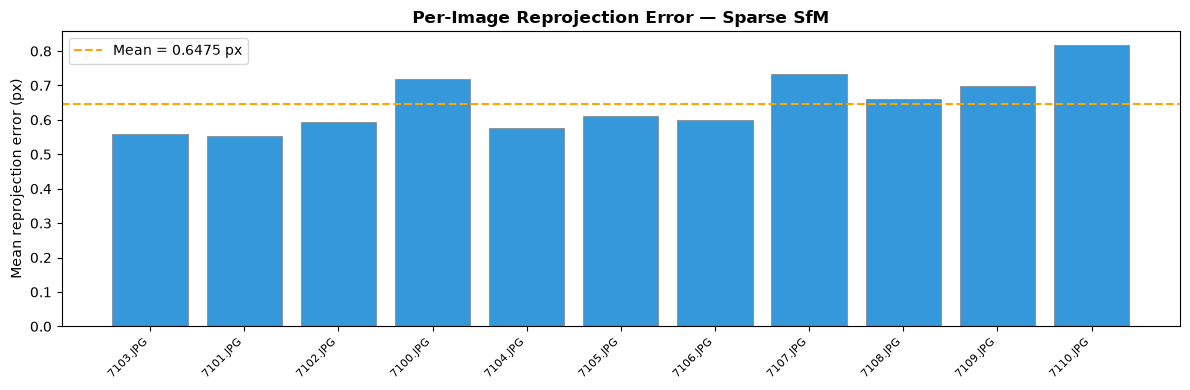

Saved → q4_data/q4_reprojection_error.png


In [17]:
# ------------------------------------------------------------------
# 8-B  Plot
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(img_names)), img_errors, color="#3498db", edgecolor="grey", linewidth=0.5)
ax.axhline(np.mean(img_errors), color="orange", linestyle="--",
           linewidth=1.5, label=f"Mean = {np.mean(img_errors):.4f} px")
ax.set_xticks(range(len(img_names)))
ax.set_xticklabels([n.replace("100_", "") for n in img_names], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Mean reprojection error (px)")
ax.set_title("Per-Image Reprojection Error — Sparse SfM", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("q4_data/q4_reprojection_error.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → q4_data/q4_reprojection_error.png")

## 9 — Camera Frustum Visualisation

We draw each camera as a pyramid (frustum) in the scene, with the apex at the
camera centre and the base at the image plane. This clearly shows the coverage
of each viewpoint around the castle.

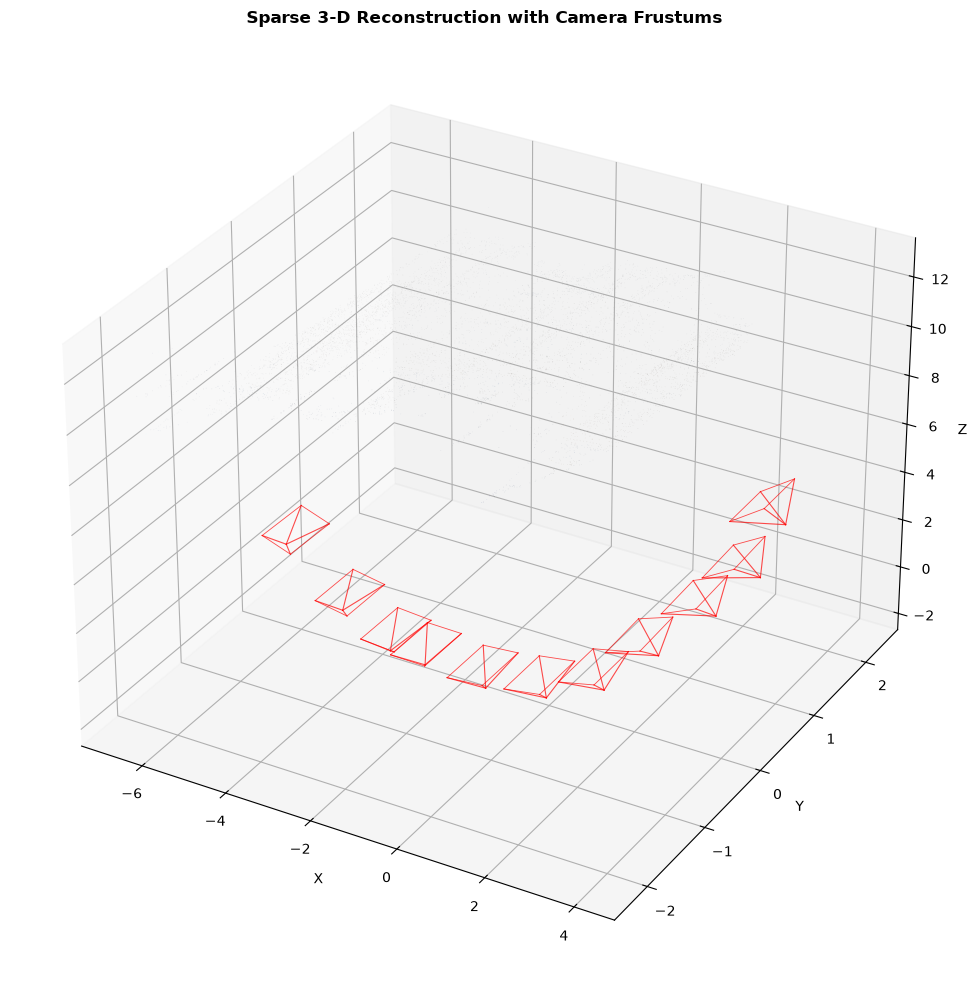

Saved → q4_data/q4_frustums.png


In [18]:
# ------------------------------------------------------------------
# 9  Draw camera frustums in matplotlib 3-D
# ------------------------------------------------------------------
def frustum_corners(C, R_cam, fx, fy, cx, cy, w, h, scale=0.5):
    """Return 5 frustum corners: apex + 4 image-plane corners."""
    # Image-plane corners in camera space at depth=scale
    corners_cam = np.array([
        [(-cx)         / fx * scale, (-cy)         / fy * scale, scale],
        [(w - cx)      / fx * scale, (-cy)         / fy * scale, scale],
        [(w - cx)      / fx * scale, (h - cy)      / fy * scale, scale],
        [(-cx)         / fx * scale, (h - cy)      / fy * scale, scale],
    ])
    # Rotate to world coords (R_cam maps world→camera, so .T maps back)
    corners_world = (R_cam.T @ corners_cam.T).T + C
    return C, corners_world

fig = plt.figure(figsize=(14, 10))
ax  = fig.add_subplot(111, projection="3d")

# Point cloud (small, grey background)
ax.scatter(xyz_c[::step, 0], xyz_c[::step, 1], xyz_c[::step, 2],
           c=rgb_c[::step] / 255.0, s=0.3, alpha=0.4, linewidths=0)

# Frustums
scale_f = (pct98 - pct2).max() * 0.1
for img in rec.images.values():
    cam    = rec.cameras[img.camera_id]
    # Use COLMAP's calibration matrix so this works with both
    # single-focal-length and separate-fx/fy camera models.
    K = np.asarray(cam.calibration_matrix(), dtype=float)
    fx, fy = float(K[0, 0]), float(K[1, 1])
    cx_p, cy_p = float(K[0, 2]), float(K[1, 2])

    R_cam = img.cam_from_world().rotation.matrix()
    C_w   = img.projection_center()

    apex, base = frustum_corners(C_w, R_cam, fx, fy, cx_p, cy_p,
                                  cam.width, cam.height, scale=scale_f)
    # Draw frustum edges
    for b in base:
        ax.plot([apex[0], b[0]], [apex[1], b[1]], [apex[2], b[2]],
                "r-", linewidth=0.8, alpha=0.7)
    for i in range(4):
        b1, b2 = base[i], base[(i+1) % 4]
        ax.plot([b1[0], b2[0]], [b1[1], b2[1]], [b1[2], b2[2]],
                "r-", linewidth=0.6, alpha=0.7)

ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title("Sparse 3-D Reconstruction with Camera Frustums", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("q4_data/q4_frustums.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → q4_data/q4_frustums.png")

## 10 — Summary

| Step | Tool | Result |
|------|------|--------|
| Feature extraction | `pycolmap.extract_features` | SIFT keypoints + descriptors |
| Feature matching | `pycolmap.match_exhaustive` | 55 image pairs verified |
| Sparse SfM | `pycolmap.incremental_mapping` | Poses + sparse point cloud |
| Export | Open3D `.ply` | `q4_data/sparse_cloud.ply` |

**Key takeaways:**
1. **COLMAP SfM** recovers accurate camera poses from unordered images purely
   from visual features — no GPS or known geometry needed.
2. The sparse point cloud clearly shows the 3-D structure of the castle facade.
3. The mean reprojection error < 1 px confirms the geometric consistency of
   the recovered poses.
4. For a **dense** point cloud, the next step would be `pycolmap.patch_match_stereo`
   followed by `patch_match_stereo_to_3D` (Multi-View Stereo), which requires a GPU.

In [19]:
print("== Q4 output files ==")
OUT_FILES = sorted(BASE_DIR.glob("q4_*")) + sorted(BASE_DIR.glob("sparse_*"))
for f in OUT_FILES:
    print(f"  {f.name:35s}  {f.stat().st_size:>12,} bytes")
print()
# Final reconstruction stats
print("== Reconstruction summary ==")
print(f"  Images registered  : {rec.num_reg_images()}")
print(f"  3-D points         : {rec.num_points3D():,}")
print(f"  Mean error (all pts): {err.mean():.4f} px")

== Q4 output files ==
  q4_frustums.png                           157,371 bytes
  q4_input_images.png                     1,074,126 bytes
  q4_point_cloud_3d.png                     168,021 bytes
  q4_point_cloud_ortho.png                  116,518 bytes
  q4_reprojection_error.png                  25,075 bytes
  sparse_cloud.ply                          213,048 bytes

== Reconstruction summary ==
  Images registered  : 11
  3-D points         : 7,883
  Mean error (all pts): 0.6092 px
